# Chapitre 2 - Cours 3 : schémas souples et langages de requête

Le cours 1 a pesé la localité, le cours 2 les jointures. Restent deux arguments du débat
entre relationnel et documents : la **souplesse du schéma** et le **langage de requête**.
Ce cours couvre la fin de la section *Relational Versus Document Databases Today*
(*Which data model leads to simpler application code?*, *Schema flexibility in the
document model*, *Convergence of document and relational databases*) et la section
*Query Languages for Data* (*Declarative Queries on the Web*, *MapReduce Querying*).

**Plan.**

1. Quel modèle simplifie le code ?
2. Schéma à la lecture, schéma à l'écriture.
3. Déclaratif contre impératif.
4. Les requêtes déclaratives sur le Web.
5. MapReduce sur des documents.
6. Le pipeline d'agrégation.
7. La convergence des modèles.

In [1]:
import json
import sqlite3
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import datamodels as dm
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Quel modèle simplifie le code ? (section *Which data model leads to simpler application code?*)

Le verdict du livre tient en deux phrases :

- si les données ont une **structure de document** (un arbre de relations un-à-plusieurs,
  chargé d'un bloc), le modèle document est probablement le bon choix. Le découpage
  relationnel d'un tel arbre en plusieurs tables, le *shredding*, donne des schémas
  lourds et du code inutilement compliqué (cours 1) ;
- si l'application a besoin de relations **plusieurs-à-plusieurs**, le modèle document
  perd son attrait : jointures émulées dans le code, dénormalisation à maintenir
  (cours 2). Et si ces relations dominent, le **graphe** devient le modèle naturel
  (cours 4).

Le modèle document a une autre limite, plus discrète : on ne peut pas désigner
**directement** un élément imbriqué. Il faut dire « le deuxième poste du profil 42 »,
une adresse **positionnelle** qui devient fausse dès que la liste change. En relationnel,
chaque poste a son propre identifiant stable. Démonstration : un autre service a retenu
l'adresse d'un poste pour y attacher une recommandation, puis l'utilisateur supprime un
ancien poste.

In [2]:
doc = {"user_id": 42, "positions": [
    {"job_title": "Architecte de données", "organization": "Datanet"},
    {"job_title": "Ingénieure logiciel", "organization": "Novasoft"},
    {"job_title": "Stagiaire", "organization": "Pixelsoft"}]}
rel = pd.DataFrame({"id": [9001, 9002, 9003], "user_id": 42,
                    "job_title": [p["job_title"] for p in doc["positions"]]})
adresse_doc = ("profil 42", "positions", 1)           # « le 2e poste du profil 42 »
adresse_rel = 9002                                    # l'identifiant du poste

del doc["positions"][0]                               # l'utilisateur supprime son poste le plus récent
rel = rel[rel.id != 9001]
pd.DataFrame({
    "référence": ["positions[1] dans le document", "positions.id = 9002"],
    "désignait": ["Ingénieure logiciel", "Ingénieure logiciel"],
    "désigne maintenant": [doc["positions"][adresse_doc[2]]["job_title"],
                           rel.loc[rel.id == adresse_rel, "job_title"].item()],
})

,référence,désignait,désigne maintenant
0,positions[1] dans le document,Ingénieure logiciel,Stagiaire
1,positions.id = 9002,Ingénieure logiciel,Ingénieure logiciel


La référence positionnelle pointe désormais sur le **mauvais** poste, sans aucune erreur.
Le remède est d'attribuer un identifiant à chaque élément imbriqué, ce qui revient à
réintroduire une idée relationnelle dans le document.

> **À retenir.** Arbre lu d'un bloc : modèle document. Relations plusieurs-à-plusieurs :
> relationnel, ou graphe si elles dominent. Un élément imbriqué dans un document n'a pas
> d'adresse stable sans identifiant propre.

## 2. Schéma à la lecture, schéma à l'écriture (section *Schema flexibility in the document model*)

Les bases documents, et le support JSON des bases relationnelles, n'imposent en général
**aucun schéma** : on peut ajouter n'importe quelle clé à un document, et le lecteur n'a
aucune garantie sur les champs présents. On les dit *schemaless*, ce qui est trompeur :
le code qui lit les données suppose bien une structure. Il existe un schéma **implicite**,
que la base ne vérifie pas. Le livre préfère parler de :

- **schéma à la lecture** (*schema-on-read*) : la structure est interprétée au moment
  où l'on lit, comme le typage **dynamique** d'un langage ;
- **schéma à l'écriture** (*schema-on-write*) : la base vérifie à chaque écriture que
  les données respectent le schéma déclaré, comme le typage **statique**.

La différence saute aux yeux quand le format change. Exemple du livre : on stockait le
nom complet dans un seul champ `name`, on veut désormais un champ `first_name` séparé.

**Schéma à l'écriture** : on migre la table. Ajouter une colonne avec une valeur par
défaut `NULL` est quasi instantané dans la plupart des bases ; mais remplir la colonne
(`UPDATE`) réécrit **chaque ligne**. Mesurons les deux étapes sur SQLite pour des tables
de taille croissante.

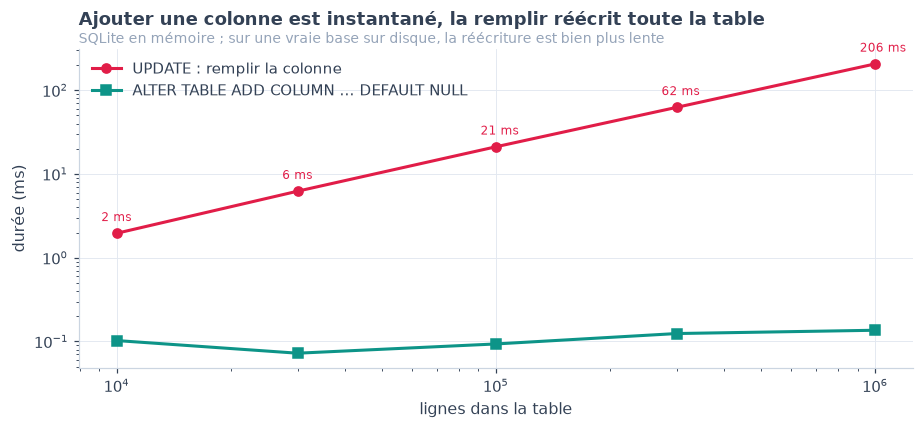

,lignes,ALTER (ms),UPDATE (ms)
0,10000,0.10,1.96
1,30000,0.07,6.22
2,100000,0.09,21.09
3,300000,0.12,62.43
4,1000000,0.14,205.93


In [3]:
def migration_cost(n):
    c = sqlite3.connect(":memory:")
    c.execute("CREATE TABLE users (id INTEGER PRIMARY KEY, name TEXT, bio TEXT)")
    c.executemany("INSERT INTO users VALUES (?, ?, ?)",
                  ((i, f"Prénom{i % 997} Nom{i}", "x" * 60) for i in range(n)))
    c.commit()
    t0 = time.perf_counter()
    c.execute("ALTER TABLE users ADD COLUMN first_name TEXT DEFAULT NULL")
    t_alter = time.perf_counter() - t0
    t0 = time.perf_counter()
    c.execute("UPDATE users SET first_name = substr(name, 1, instr(name, ' ') - 1)")
    c.commit()
    t_update = time.perf_counter() - t0
    assert c.execute("SELECT first_name FROM users WHERE id = 5").fetchone()[0] == "Prénom5"
    return t_alter * 1e3, t_update * 1e3

tailles = [10_000, 30_000, 100_000, 300_000, 1_000_000]
mig = pd.DataFrame([(n, *migration_cost(n)) for n in tailles], columns=["lignes", "ALTER (ms)", "UPDATE (ms)"])

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.loglog(mig["lignes"], mig["UPDATE (ms)"], marker="o", color=ROSE, label="UPDATE : remplir la colonne")
ax.loglog(mig["lignes"], mig["ALTER (ms)"], marker="s", color=TEAL, label="ALTER TABLE ADD COLUMN ... DEFAULT NULL")
for x, y in zip(mig["lignes"], mig["UPDATE (ms)"]):
    ax.annotate(f"{y:.0f} ms", (x, y), (-10, 8), textcoords="offset points", fontsize=8, color=ROSE)
ax.set_xlabel("lignes dans la table"); ax.set_ylabel("durée (ms)")
ax.set_title("Ajouter une colonne est instantané, la remplir réécrit toute la table")
subtitle(ax, "SQLite en mémoire ; sur une vraie base sur disque, la réécriture est bien plus lente")
ax.legend(); plt.tight_layout(); plt.show()
mig.round(2)

L'`ALTER TABLE` reste sous la milliseconde quelle que soit la taille (SQLite ne fait que
modifier le schéma enregistré), tandis que l'`UPDATE` croît linéairement. Sur une base de
production de plusieurs téraoctets, cette réécriture prend des heures, verrouille ou
alourdit la table et génère un énorme volume de journal ; des outils existent pour
migrer en arrière-plan sans interruption, mais l'opération reste délicate. On peut
l'éviter en ajoutant la colonne à `NULL` et en la remplissant **à la lecture**... ce qui
revient à faire du schéma à la lecture dans une base relationnelle.

**Schéma à la lecture** : on écrit simplement les nouveaux documents avec le nouveau
champ, et le code de lecture traite les anciens :

In [4]:
def read_user(user):
    """Lecteur tolérant : les documents écrits avant la migration n'ont pas first_name."""
    if user and user.get("name") and not user.get("first_name"):
        user = dict(user, first_name=user["name"].split(" ")[0])
    return user

print(read_user({"name": "Inès Martin"}))
print(read_user({"name": "Inès Martin", "first_name": "Inès"}))

{'name': 'Inès Martin', 'first_name': 'Inès'}
{'name': 'Inès Martin', 'first_name': 'Inès'}


L'inconvénient : **chaque** partie de l'application qui lit ces documents doit gérer
**tous** les formats passés, potentiellement écrits il y a des années. Simulons la vie
d'une collection de 100 000 documents sur huit ans, avec un changement de format par an.
Un document n'est réécrit au format courant que lorsqu'il est modifié (ici, 30 % des
documents par an), et de nouveaux documents arrivent.

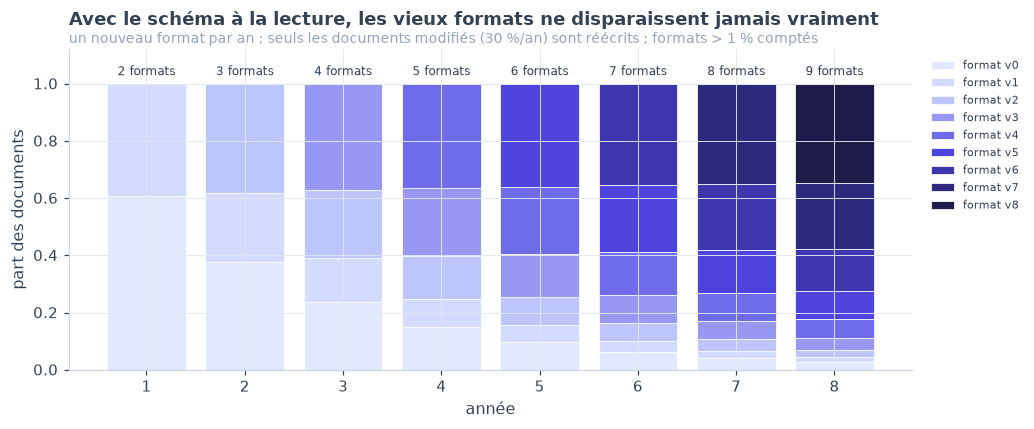

In [5]:
n_docs, years = 100_000, 8
version = np.zeros(n_docs, dtype=int)
hist = []
for y in range(1, years + 1):
    touched = rng.random(version.size) < 0.30
    version[touched] = y
    version = np.concatenate([version, np.full(15_000, y)])
    hist.append(np.bincount(version, minlength=years + 1))
hist = np.array(hist)

fig, ax = plt.subplots(figsize=(9.5, 4))
bottom = np.zeros(years)
cmap = plt.get_cmap("ddia_seq")
for v in range(years + 1):
    frac = hist[:, v] / hist.sum(axis=1)
    ax.bar(np.arange(1, years + 1), frac, bottom=bottom, color=cmap(0.15 + 0.85 * v / years),
           edgecolor="white", lw=0.5, label=f"format v{v}")
    bottom += frac
for y in range(years):
    n_formats = (hist[y] > 0.01 * hist[y].sum()).sum()
    ax.text(y + 1, 1.03, f"{n_formats} formats", ha="center", fontsize=8, color=SLATE)
ax.set_xlabel("année"); ax.set_ylabel("part des documents"); ax.set_ylim(0, 1.12)
ax.set_title("Avec le schéma à la lecture, les vieux formats ne disparaissent jamais vraiment")
subtitle(ax, "un nouveau format par an ; seuls les documents modifiés (30 %/an) sont réécrits ; formats > 1 % comptés")
ax.legend(fontsize=7.5, loc="upper left", bbox_to_anchor=(1.01, 1.0)); plt.tight_layout(); plt.show()

Après huit ans, les neuf formats successifs pèsent encore chacun plus de 1 % des
documents : le code de lecture doit tous les comprendre. Le schéma à l'écriture concentre ce coût dans la migration ; le schéma à
la lecture le dilue dans tout le code, pour toujours.

**Quand le schéma à la lecture l'emporte-t-il ?** Quand les données sont
**hétérogènes** : de nombreux types d'objets qu'il serait absurde de ranger chacun dans
sa table, ou une structure dictée par des **systèmes externes** qui peuvent la changer à
tout moment. Exemple : des événements reçus de trois fournisseurs de paiement.

In [6]:
fournisseurs = {
    "A": lambda i: {"id": i, "amount": 10.0, "currency": "EUR", "status": "ok"},
    "B": lambda i: {"txn": i, "amount_cents": 1000, "meta": {"country": "FR"}, "state": "SETTLED"},
    "C": lambda i: {"id": i, "value": {"amount": "10.00", "ccy": "EUR"}, "events": ["created", "paid"],
                    **({"refund": True} if i % 7 == 0 else {})},
}
evts = [fournisseurs[f](i) for i in range(3000) for f in "ABC" if rng.random() < 0.6]
formes = Counter(tuple(sorted(e)) for e in evts)
pd.DataFrame({"ensemble de clés": [", ".join(k) for k in formes], "documents": list(formes.values())})

,ensemble de clés,documents
0,"amount, currency, id, status",1830
1,"amount_cents, meta, state, txn",1845
2,"events, id, refund, value",243
3,"events, id, value",1507


Quatre « formes » différentes coexistent (le fournisseur C ajoute un champ `refund`
certains jours) : un schéma relationnel strict demanderait une table par forme, et une
migration à chaque caprice d'un fournisseur. Ici, des documents sans schéma sont plus
naturels. Mais quand tous les enregistrements ont la même structure, un schéma est un
excellent moyen de la **documenter** et de la **faire respecter**. Nous reviendrons sur
l'évolution des schémas au chapitre 4.

> **À retenir.** « Sans schéma » signifie « schéma implicite, vérifié à la lecture ». Le
> schéma à l'écriture paie le changement de format en une migration (rapide pour
> ajouter une colonne, lente pour réécrire les lignes) ; le schéma à la lecture le paie
> dans tout le code lecteur, indéfiniment. Il gagne pour les données hétérogènes.

## 3. Déclaratif contre impératif (section *Query Languages for Data*)

SQL, comme Cypher, SPARQL et Datalog que nous verrons ensuite, est **déclaratif** : on
décrit **ce que** l'on veut (quelles conditions, quels tris, quels regroupements), pas
**comment** l'obtenir. Un langage de programmation comme Python est **impératif** : on
écrit l'algorithme, opération par opération. Exemple du livre : la liste des requins
parmi des observations d'animaux marins.

In [7]:
obs = dm.make_observations(200_000, seed=1)

def sharks_imperative(observations):
    result = []
    for o in observations:                     # l'ordre de parcours est imposé
        if o["family"] == "Sharks":
            result.append(o)
    return result

oc = sqlite3.connect(":memory:")
oc.execute("CREATE TABLE observations (id INTEGER PRIMARY KEY, ts TEXT, family TEXT, species TEXT, num_animals INTEGER)")
oc.executemany("INSERT INTO observations VALUES (?, ?, ?, ?, ?)",
               [(o["_id"], o["observationTimestamp"], o["family"], o["species"], o["numAnimals"]) for o in obs])
SQL_SHARKS = "SELECT * FROM observations WHERE family = 'Sharks'"
assert len(sharks_imperative(obs)) == len(oc.execute(SQL_SHARKS).fetchall())
print(f"{len(sharks_imperative(obs)):,} observations de requins sur {len(obs):,}".replace(",", " "))

59 838 observations de requins sur 200 000


Le déclaratif est plus concis, mais son vrai atout est ailleurs : il **cache
l'implémentation**, ce qui laisse la base libre de l'améliorer sans toucher aux requêtes.
Créons un index sur `family` : la requête SQL, inchangée, change de plan d'exécution.
Le code impératif, lui, ne profiterait d'un index que si on le réécrivait.

In [8]:
def sql_time(sql, n=20):
    t0 = time.perf_counter()
    for _ in range(n):
        oc.execute(sql).fetchall()
    return (time.perf_counter() - t0) / n * 1e3

SQL_RARE = ("SELECT COUNT(*), SUM(num_animals) FROM observations "
            "WHERE family = 'Rays' AND species = 'Raie manta' AND num_animals >= 8")
avant = (" | ".join(r[-1] for r in oc.execute("EXPLAIN QUERY PLAN " + SQL_RARE)), sql_time(SQL_RARE))
oc.execute("CREATE INDEX obs_fsn ON observations (family, species, num_animals)")
apres = (" | ".join(r[-1] for r in oc.execute("EXPLAIN QUERY PLAN " + SQL_RARE)), sql_time(SQL_RARE))
pd.DataFrame({"index": ["aucun", "(family, species, num_animals)"], "plan choisi par SQLite": [avant[0], apres[0]],
              "ms par requête": [avant[1], apres[1]]})

,index,plan choisi par SQLite,ms par requête
0,aucun,SCAN observations,5.600
1,"(family, species, num_animals)",SEARCH observations USING COVERING INDEX obs_fsn (family=? AND species=? AND num_anima...,0.019


Même texte de requête, plan différent : un parcours complet de la table devient une
recherche dans un index **couvrant** (il contient toutes les colonnes utiles), et la
requête, qui ne concerne qu'une centaine de lignes, devient des dizaines de fois plus
rapide.

Le second atout est le **parallélisme**. Une requête déclarative ne fixe aucun ordre :
le moteur peut découper les données entre plusieurs cœurs ou machines et combiner les
résultats partiels, à condition que l'agrégat s'y prête (une somme se calcule par
morceaux puis s'additionne). Le code impératif ci-dessus, avec son `append` dans une
liste partagée, impose un ordre séquentiel ; le paralléliser serait un travail à part
entière. Montrons le découpage qu'un moteur pourrait faire.

In [9]:
chunks = np.array_split(np.arange(len(obs)), 4)
partiels = [sum(obs[i]["numAnimals"] for i in idx if obs[i]["family"] == "Sharks") for idx in chunks]
total = sum(o["numAnimals"] for o in obs if o["family"] == "Sharks")
print("sommes partielles par morceau :", partiels, "-> total", sum(partiels), "=", total)

sommes partielles par morceau : [33910, 33335, 33408, 32927] -> total 133580 = 133580


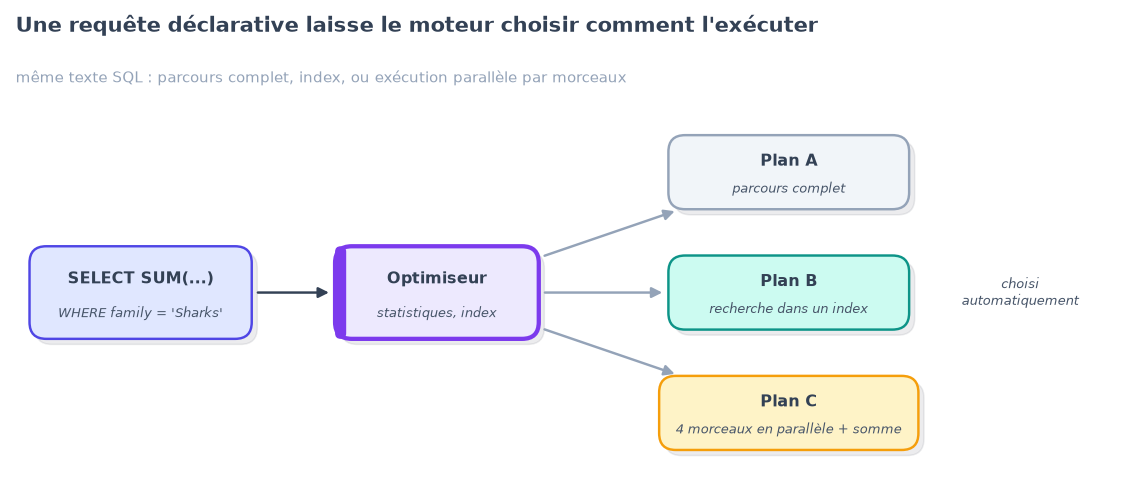

In [10]:
d = Diagram(12, 4.2, title="Une requête déclarative laisse le moteur choisir comment l'exécuter",
            subtitle="même texte SQL : parcours complet, index, ou exécution parallèle par morceaux")
d.box("q", 1.4, 2.1, "SELECT SUM(...)", sub="WHERE family = 'Sharks'", color=INDIGO, w=2.4, h=1.0)
d.box("opt", 4.6, 2.1, "Optimiseur", sub="statistiques, index", color=VIOLET, kind="model", w=2.2, h=1.0)
d.box("p1", 8.4, 3.4, "Plan A", sub="parcours complet", color=GRAY, w=2.6, h=0.8)
d.box("p2", 8.4, 2.1, "Plan B", sub="recherche dans un index", color=TEAL, w=2.6, h=0.8)
d.box("p3", 8.4, 0.8, "Plan C", sub="4 morceaux en parallèle + somme", color=AMBER, w=2.8, h=0.8)
d.arrow("q", "opt")
for p in ["p1", "p2", "p3"]:
    d.arrow("opt", p, color=GRAY)
d.note(10.9, 2.1, "choisi\nautomatiquement", fontsize=8.5)
d.show()

> **À retenir.** Un langage déclaratif décrit le résultat voulu, pas l'algorithme. Il est
> plus concis et surtout il laisse l'optimiseur choisir les index, l'ordre des jointures
> et le parallélisme, et en changer sans qu'on réécrive les requêtes.

## 4. Les requêtes déclaratives sur le Web (section *Declarative Queries on the Web*)

L'avantage du déclaratif dépasse les bases de données. Le livre prend l'exemple d'une
page web : on veut que le titre de la page actuellement sélectionnée dans un menu
apparaisse sur fond bleu. En **CSS**, une ligne suffit : `li.selected > p { background:
blue; }`, le sélecteur décrivant le **motif** des éléments concernés. En JavaScript
**impératif**, avec l'API du DOM, il faut parcourir les éléments, tester leur classe,
descendre dans leurs enfants, et modifier le style à la main.

Reproduisons les deux approches sur un petit arbre de document.

In [11]:
page = {"tag": "ul", "cls": set(), "children": [
    {"tag": "li", "cls": {"selected"}, "children": [{"tag": "p", "cls": set(), "text": "Requins", "children": []},
                                                     {"tag": "ul", "cls": set(), "children": [
                                                         {"tag": "li", "cls": set(), "children": [
                                                             {"tag": "p", "cls": set(), "text": "Requin-tigre", "children": []}]}]}]},
    {"tag": "li", "cls": set(), "children": [{"tag": "p", "cls": set(), "text": "Baleines", "children": []}]},
]}

def css_select(node, parent_tag, parent_cls, child_tag, parent=None):
    """Sélecteur déclaratif `parent_tag.parent_cls > child_tag` : le moteur parcourt pour nous."""
    out = []
    if parent is not None and node["tag"] == child_tag and parent["tag"] == parent_tag and parent_cls in parent["cls"]:
        out.append(node)
    for ch in node["children"]:
        out += css_select(ch, parent_tag, parent_cls, child_tag, node)
    return out

def imperative_highlight(root):
    """Style impératif : parcourir, tester, modifier ; et ne rien défaire si la sélection change."""
    stack = [root]
    while stack:
        el = stack.pop()
        if el["tag"] == "li" and "selected" in el["cls"]:
            for ch in el["children"]:
                if ch["tag"] == "p":
                    ch["style"] = "blue"
        stack.extend(el["children"])

imperative_highlight(page)
print("CSS        :", [n["text"] for n in css_select(page, "li", "selected", "p")])
page["children"][0]["cls"].discard("selected"); page["children"][1]["cls"].add("selected")   # l'utilisateur clique
imperative_highlight(page)
print("après clic, CSS        :", [n["text"] for n in css_select(page, "li", "selected", "p")])
print("après clic, impératif  :", [n["text"] for n in [page["children"][0]["children"][0], page["children"][1]["children"][0]]
                                   if n.get("style") == "blue"])

CSS        : ['Requins']
après clic, CSS        : ['Baleines']
après clic, impératif  : ['Requins', 'Baleines']


Après le clic, le sélecteur CSS désigne automatiquement le nouvel élément ; le code
impératif, lui, laisse **les deux** titres en bleu, car personne n'a écrit le code qui
retire le style de l'ancien. Le code impératif est plus long, plus fragile, et lié à
l'implémentation (un navigateur pourrait accélérer CSS sans casser la page ; il ne peut
rien faire pour notre boucle). Les bases de données profitent exactement du même
avantage avec SQL.

> **À retenir.** CSS face à la manipulation du DOM illustre la même opposition que SQL
> face au code impératif : décrire le motif plutôt que l'algorithme rend le code plus
> court, plus robuste aux changements, et améliorable par le moteur.

## 5. MapReduce sur des documents (section *MapReduce Querying*)

**MapReduce**, popularisé par Google, est un modèle pour traiter de grands volumes de
données sur de nombreuses machines (chapitre 10). Certaines bases NoSQL, dont
MongoDB et CouchDB, en proposent une forme limitée pour interroger leurs documents. Le
modèle se situe **entre** le déclaratif et l'impératif : la logique est écrite sous forme
de deux fonctions de code, mais c'est le moteur qui les appelle et décide où et quand.

- la fonction **map** est appelée une fois par document et **émet** des paires (clé,
  valeur) ;
- les paires sont **regroupées par clé** ;
- la fonction **reduce** est appelée une fois par clé avec toutes ses valeurs.

Les deux fonctions doivent être **pures** : sans effet de bord, sans requête
supplémentaire, ne dépendant que de leurs arguments. C'est ce qui permet au moteur de
les exécuter n'importe où, dans n'importe quel ordre, et de les relancer en cas de panne.
L'exemple du livre : le nombre de requins observés par mois.

In [12]:
def mapper(doc, emit):
    emit(doc["observationTimestamp"][:7], doc["numAnimals"])    # clé : « AAAA-MM »

def reducer(key, values):
    return sum(values)

st = {}
par_mois = dm.map_reduce(obs, mapper, reducer, query={"family": "Sharks"}, stats=st)
print(st)
dict(sorted(par_mois.items())[:4])

{'documents': 59838, 'emissions': 59838, 'cles': 12}


{'2017-01': 5637, '2017-02': 5084, '2017-03': 5433, '2017-04': 5556}

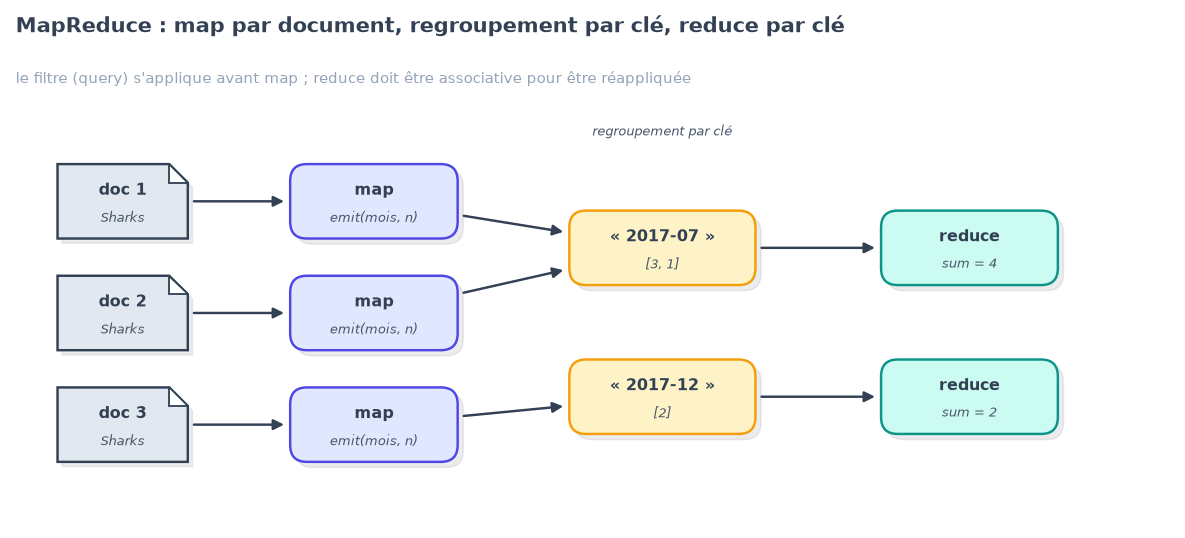

In [13]:
d = Diagram(12.5, 4.6, title="MapReduce : map par document, regroupement par clé, reduce par clé",
            subtitle="le filtre (query) s'applique avant map ; reduce doit être associative pour être réappliquée")
for k, (x, t) in enumerate([(1.2, "doc 1"), (1.2, "doc 2"), (1.2, "doc 3")]):
    d.box(f"d{k}", x, 3.5 - 1.2 * k, t, sub="Sharks", color=SLATE, kind="doc", w=1.4, h=0.8)
    d.box(f"m{k}", 3.9, 3.5 - 1.2 * k, "map", sub="emit(mois, n)", color=INDIGO, w=1.8, h=0.8)
    d.arrow(f"d{k}", f"m{k}")
d.box("g1", 7.0, 3.0, "« 2017-07 »", sub="[3, 1]", color=AMBER, w=2.0, h=0.8)
d.box("g2", 7.0, 1.4, "« 2017-12 »", sub="[2]", color=AMBER, w=2.0, h=0.8)
d.arrow("m0", "g1"); d.arrow("m1", "g1"); d.arrow("m2", "g2")
d.box("r1", 10.3, 3.0, "reduce", sub="sum = 4", color=TEAL, w=1.9, h=0.8)
d.box("r2", 10.3, 1.4, "reduce", sub="sum = 2", color=TEAL, w=1.9, h=0.8)
d.arrow("g1", "r1"); d.arrow("g2", "r2")
d.note(7.0, 4.25, "regroupement par clé", fontsize=8.5)
d.show()

Comme les fonctions sont pures, on peut répartir les documents sur quatre « machines »,
appliquer MapReduce sur chacune, puis réduire les résultats partiels : on retrouve le
même résultat. C'est possible parce que la somme est **associative** ; MongoDB peut
d'ailleurs rappeler `reduce` sur ses propres sorties.

In [14]:
morceaux = [obs[i::4] for i in range(4)]
partiels = [dm.map_reduce(m, mapper, reducer, query={"family": "Sharks"}) for m in morceaux]
fusion = {}
for p in partiels:
    for k, v in p.items():
        fusion[k] = reducer(k, [fusion[k], v]) if k in fusion else v
assert fusion == par_mois
print("4 morceaux traités séparément puis fusionnés : résultat identique")

4 morceaux traités séparément puis fusionnés : résultat identique


MapReduce est un modèle de bas niveau pour l'exécution distribuée. Son défaut, dans une
base de données, est d'obliger à écrire **deux fonctions soigneusement coordonnées**, ce
qui est souvent plus difficile qu'une requête unique, et de priver l'optimiseur de toute
marge de manœuvre. C'est pourquoi MongoDB a ajouté un langage déclaratif, le **pipeline
d'agrégation** (section suivante). Le mouvement NoSQL réinvente là, non sans ironie, un
SQL à la syntaxe JSON.

> **À retenir.** MapReduce exprime une requête par deux fonctions pures (map, reduce)
> que le moteur distribue à sa guise. Plus souple que SQL mais plus laborieux, il a été
> largement remplacé dans les bases documents par des langages déclaratifs.

## 6. Le pipeline d'agrégation, un langage de requête pour documents (section *MapReduce Querying*)

Les langages de requête des bases documents sont plus variés que SQL : certaines bases
n'offrent que l'accès par clé primaire, d'autres des index secondaires sur des valeurs
imbriquées, d'autres de vrais langages. Les bases XML ont XQuery et XPath ; JSON a ses
équivalents de XPath (JSON Pointer, JSONPath) ; MongoDB a son **pipeline d'agrégation**.

Reprenons l'exemple de la biologiste marine : le nombre de requins observés chaque mois.
En SQL (dialecte PostgreSQL dans le livre, SQLite ici) :

In [15]:
SQL_MOIS = """SELECT substr(ts, 1, 7) AS mois, SUM(num_animals) AS total
                FROM observations WHERE family = 'Sharks' GROUP BY mois ORDER BY mois"""
sql_res = oc.execute(SQL_MOIS).fetchall()
sql_res[:3]

[('2017-01', 5637), ('2017-02', 5084), ('2017-03', 5433)]

Le même calcul en pipeline d'agrégation, exécuté par notre mini-moteur `dm.aggregate`
(qui implémente `$match`, `$group`, `$sort`, `$unwind`, `$lookup`, `$project`...) :

In [16]:
PIPE = [
    {"$match": {"family": "Sharks"}},
    {"$group": {"_id": {"year": {"$year": "$observationTimestamp"},
                        "month": {"$month": "$observationTimestamp"}},
                "totalAnimals": {"$sum": "$numAnimals"}}},
    {"$sort": {"_id.year": 1, "_id.month": 1}},
]
etapes = {}
pipe_res = dm.aggregate(obs, PIPE, stats=etapes)
assert [(f"{r['_id']['year']}-{r['_id']['month']:02d}", r["totalAnimals"]) for r in pipe_res] == sql_res
pipe_res[:3]

[{'_id': {'year': 2017, 'month': 1}, 'totalAnimals': 5637},
 {'_id': {'year': 2017, 'month': 2}, 'totalAnimals': 5084},
 {'_id': {'year': 2017, 'month': 3}, 'totalAnimals': 5433}]

Les deux langages ont la même expressivité sur cet exemple (le pipeline équivaut à peu
près à un sous-ensemble de SQL) ; l'un s'écrit comme une phrase anglaise, l'autre comme
du JSON. Un pipeline se lit comme une **chaîne d'étapes** : chacune reçoit le flot de
documents de la précédente. Visualisons le volume qui traverse chaque étape, sur un
pipeline plus riche : les employeurs les plus fréquents dans nos CV.

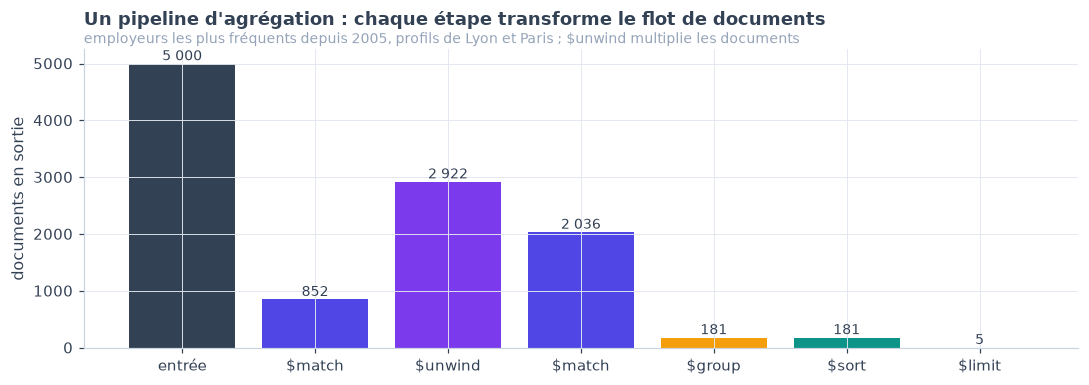

,_id,postes
0,Terracorp,429
1,Atlassys,193
2,Cieltech,141
3,Briotech,92
4,Cloudmetrics,82


In [17]:
profiles = dm.make_profiles(5000, seed=0)
PIPE2 = [
    {"$match": {"region_id": {"$in": ["fr:69", "fr:75"]}}},
    {"$unwind": "$positions"},
    {"$match": {"positions.start": {"$gte": 2005}}},
    {"$group": {"_id": "$positions.organization", "postes": {"$sum": 1}}},
    {"$sort": {"postes": -1}},
    {"$limit": 5},
]
st2 = {}
top = dm.aggregate(profiles, PIPE2, stats=st2)
fig, ax = plt.subplots(figsize=(10, 3.6))
labels = ["entrée"] + [k.split(":")[1] for k in st2]
vals = [len(profiles)] + list(st2.values())
ax.bar(range(len(vals)), vals, color=[SLATE, INDIGO, VIOLET, INDIGO, AMBER, TEAL, TEAL])
ax.set_xticks(range(len(vals)), labels)
for i, v in enumerate(vals):
    ax.text(i, v + 60, fmt(v), ha="center", fontsize=9, color=SLATE)
ax.set_ylabel("documents en sortie")
ax.set_title("Un pipeline d'agrégation : chaque étape transforme le flot de documents")
subtitle(ax, "employeurs les plus fréquents depuis 2005, profils de Lyon et Paris ; $unwind multiplie les documents")
plt.tight_layout(); plt.show()
pd.DataFrame(top)

`$unwind` **déplie** chaque profil en autant de documents qu'il a de postes (le flot
grossit), puis `$group` les agrège par employeur. C'est exactement ce que ferait une
jointure entre `users` et `positions` suivie d'un `GROUP BY`.

> **À retenir.** Le pipeline d'agrégation de MongoDB est un langage déclaratif à syntaxe
> JSON, d'expressivité comparable à un sous-ensemble de SQL : filtrer, déplier,
> regrouper, trier, joindre (`$lookup`). Le choix entre les deux syntaxes est en partie
> affaire de goût.